# Laboratorio 9 - Task 3: difusión condicional con guía sin clasificador

En esta parte entrenamos una U-Net pequeña que predice el ruido $\epsilon$ a partir de $x_t$, del instante $t$ y de una clase $c$. Con ella generamos imágenes mediante el muestreo ancestral y medimos el efecto de la guía sin clasificador sobre la fidelidad y la diversidad.

Todo el código reutilizable vive en `src/difusion.py` (con pruebas en `tests/test_difusion.py`). El calendario lineal y la función `q_sample` son los mismos de la Task 2.1.

## 0. Preparación

Usamos la misma semilla 3045 de las Tasks 1 y 2. El entrenamiento corre en GPU si está disponible.

In [1]:
from pathlib import Path
import random
import sys
import time

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.difusion import (
    NULL_CLASS, Classifier, UNet, confusion_matrix, diversity_per_class,
    fidelity, interval_losses, linear_schedule, predict, sample,
    train_classifier_epoch, train_epoch,
)

SEED = 3045
T = 1000
EPOCHS = 30
BATCH_SIZE = 128
LR = 2e-4
P_UNCOND = 0.1
W_VALUES = [1, 3, 7]

DATA_DIR = ROOT / "data"
CHECKPOINT_DIR = ROOT / "checkpoints" / "task3"
OUTPUT_DIR = ROOT / "outputs" / "task3"
ARTIFACT_DIR = ROOT / "artifacts" / "task3"
for folder in (CHECKPOINT_DIR, OUTPUT_DIR, ARTIFACT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
print(f"Semilla: {SEED}")
print(f"Dispositivo: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"PyTorch: {torch.__version__}")

Semilla: 3045
Dispositivo: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)
PyTorch: 2.14.0+cu126


## 1. Datos

Seguimos el mismo corte de la Task 1.1: las primeras 55 000 imágenes de entrenamiento entrenan y las últimas 5 000 validan. Los píxeles pasan de $[0,255]$ a $[-1,1]$ con $x \mapsto 2\,x/255 - 1$, que es la misma transformación que `ToTensor` seguido de `Normalize(0.5, 0.5)` en la Task 2.

In [2]:
raw = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
labels_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

# (60000, 28, 28) uint8 -> (60000, 1, 28, 28) en [-1, 1]
images = raw.data.unsqueeze(1).float() / 255.0 * 2 - 1
targets = raw.targets

x_train, y_train = images[:55_000], targets[:55_000]
x_val, y_val = images[55_000:], targets[55_000:]

train_loader = DataLoader(
    TensorDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=500, shuffle=False)

print("train / val:", len(x_train), len(x_val))
print(f"rango de píxeles: [{images.min():.1f}, {images.max():.1f}]")
assert len(x_train) == 55_000 and len(x_val) == 5_000

train / val: 55000 5000
rango de píxeles: [-1.0, 1.0]


## 2. Task 3.1 - U-Net condicional

La red tiene dos niveles de resolución. A $28\times28$ trabaja con 32 canales; una convolución con stride 2 baja a $14\times14$ con 64 canales, donde está el cuello de botella. El camino de subida concatena las características del mismo nivel (conexiones de salto) y termina con una convolución a un canal.

El instante entra con el embedding sinusoidal de la Semana 6,

$$\text{PE}(t,2i)=\sin\!\left(\frac{t}{10000^{2i/d}}\right),\qquad \text{PE}(t,2i+1)=\cos\!\left(\frac{t}{10000^{2i/d}}\right),$$

seguido de un MLP. La clase entra con `nn.Embedding(11, d)`, donde la clase 10 es la condición nula. Ambos vectores se suman y cada bloque proyecta esa suma a sus canales y la añade a todos los píxeles por broadcasting.

In [3]:
model = UNet(emb_dim=128).to(DEVICE)

# prueba de forma: la salida tiene que tener la forma de x_t
x_probe = torch.randn(4, 1, 28, 28, device=DEVICE)
t_probe = torch.tensor([1, 250, 750, 1000], device=DEVICE)
c_probe = torch.tensor([0, 5, 9, NULL_CLASS], device=DEVICE)
with torch.no_grad():
    out_probe = model(x_probe, t_probe, c_probe)
assert out_probe.shape == x_probe.shape

n_params = sum(p.numel() for p in model.parameters())
print("forma de entrada:", tuple(x_probe.shape), "| forma de salida:", tuple(out_probe.shape))
print(f"Parámetros totales: {n_params:,}")

forma de entrada: (4, 1, 28, 28) | forma de salida: (4, 1, 28, 28)
Parámetros totales: 395,009


## 3. Task 3.2 - Entrenamiento

En cada iteración, para cada imagen del lote, sorteamos $t\sim\mathcal{U}\{1,\dots,T\}$ y $\epsilon\sim\mathcal{N}(0,I)$, construimos $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$ con `q_sample`, reemplazamos la clase por la nula con probabilidad 0.1 y minimizamos

$$\mathcal{L}=\lVert \epsilon-\epsilon_\theta(x_t,t,c)\rVert^2 .$$

Cada época guarda un checkpoint, así que si la ejecución se corta se reanuda desde la última época completa.

In [4]:
betas, alphas, alpha_bars = linear_schedule(T)
alpha_bars_dev = alpha_bars.to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
ckpt_path = CHECKPOINT_DIR / "unet_last.pt"
history = []
if ckpt_path.exists():
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    history = ckpt["history"]
    print(f"Reanudando desde la época {len(history) + 1}")

train_start = time.perf_counter()
for epoch in range(len(history) + 1, EPOCHS + 1):
    t0 = time.perf_counter()
    loss = train_epoch(model, train_loader, optimizer, alpha_bars_dev, P_UNCOND, DEVICE)
    history.append(loss)
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "history": history}, ckpt_path)
    print(f"época {epoch:2d}/{EPOCHS} | pérdida {loss:.4f} | {time.perf_counter() - t0:.1f} s")
print(f"Tiempo de esta ejecución: {time.perf_counter() - train_start:.1f} s")

Reanudando desde la época 31
Tiempo de esta ejecución: 0.0 s


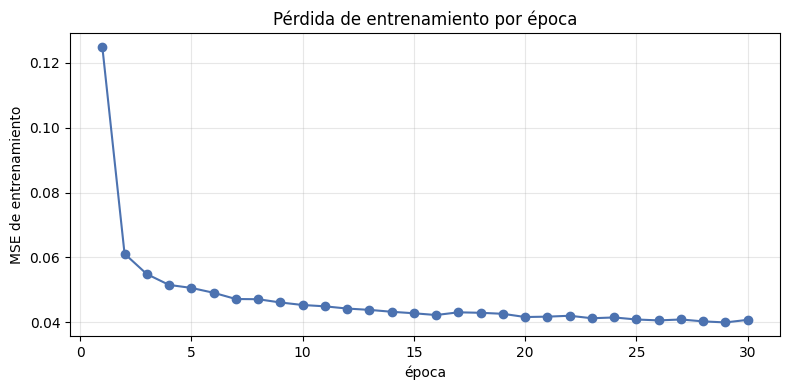

Pérdida en la época 1: 0.1250 | en la época 30: 0.0408


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(history) + 1), history, marker="o", color="#4C72B0")
ax.set_xlabel("época")
ax.set_ylabel("MSE de entrenamiento")
ax.set_title("Pérdida de entrenamiento por época")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "perdida_entrenamiento.png", dpi=120)
plt.show()
print(f"Pérdida en la época 1: {history[0]:.4f} | en la época {len(history)}: {history[-1]:.4f}")

Al terminar evaluamos sobre las 5 000 imágenes de validación la pérdida media en cada uno de los 10 intervalos de $t$ de 100 pasos. Dentro de cada intervalo $t$ se sortea de forma uniforme, la clase es la real y el ruido sale de un generador fijo para que todos los intervalos se comparen con los mismos sorteos.

 intervalo de t |  MSE val
---------------------------
          1-100 |   0.2166
        101-200 |   0.0828
        201-300 |   0.0472
        301-400 |   0.0279
        401-500 |   0.0156
        501-600 |   0.0077
        601-700 |   0.0032
        701-800 |   0.0013
        801-900 |   0.0007
       901-1000 |   0.0007


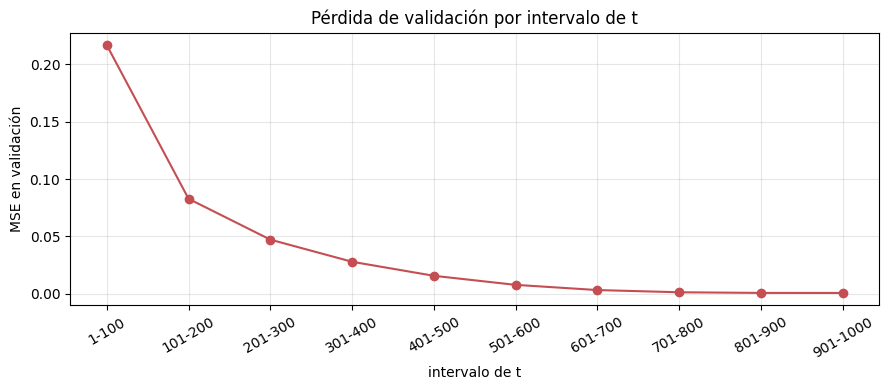

In [6]:
val_by_interval = interval_losses(model, val_loader, alpha_bars_dev, DEVICE, n_intervals=10, seed=SEED)
interval_labels = [f"{100 * k + 1}-{100 * (k + 1)}" for k in range(10)]

print(f"{'intervalo de t':>15} | {'MSE val':>8}")
print("-" * 27)
for name, value in zip(interval_labels, val_by_interval):
    print(f"{name:>15} | {value:8.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(interval_labels, val_by_interval, marker="o", color="#C44E52")
ax.set_xlabel("intervalo de t")
ax.set_ylabel("MSE en validación")
ax.set_title("Pérdida de validación por intervalo de t")
ax.grid(alpha=0.3)
plt.setp(ax.get_xticklabels(), rotation=30)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "perdida_por_intervalo.png", dpi=120)
plt.show()

## 4. Task 3.3 - Muestreo ancestral

Partimos de $x_T\sim\mathcal{N}(0,I)$ y para $t=T,\dots,1$ aplicamos

$$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\,\hat\epsilon\right)+\sigma_t z,\qquad \sigma_t^2=\beta_t,$$

con $z=0$ en el último paso. Aquí usamos solo la predicción condicional ($w=1$) y recortamos el resultado a $[-1,1]$.

forma: (100, 1, 28, 28) | rango: [-1.00, 1.00]


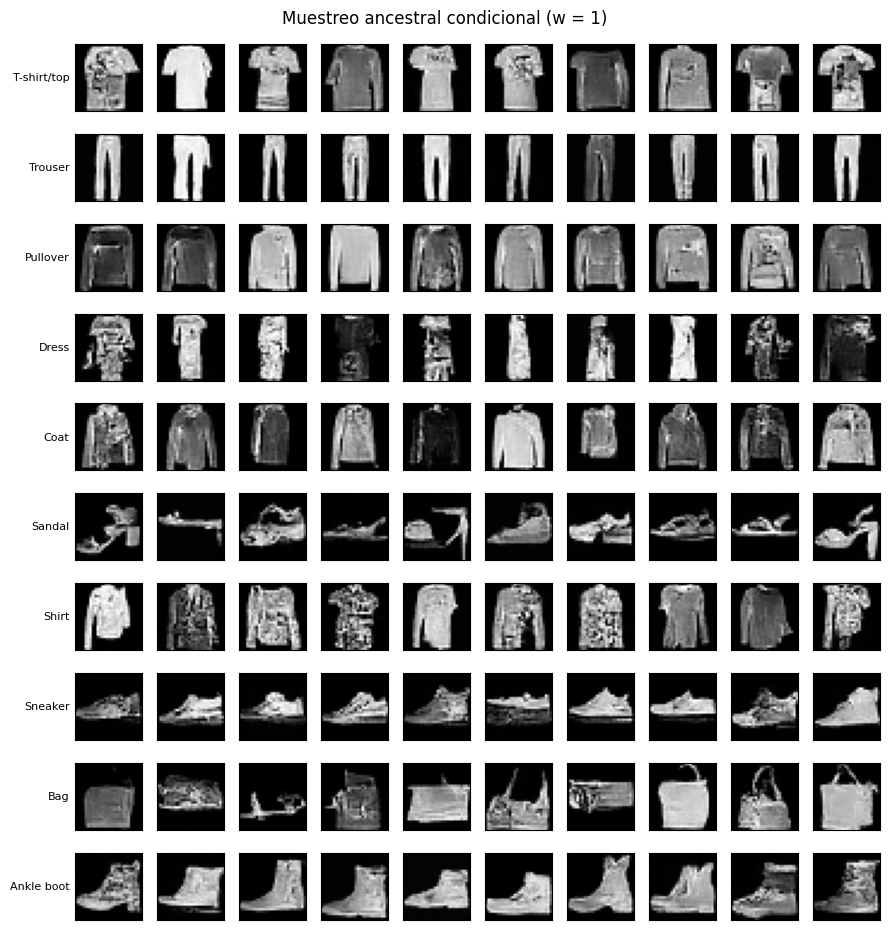

In [7]:
def show_class_grid(imgs, n_per_row, title, path):
    # una fila por clase; los valores van de [-1, 1] a [0, 1] para mostrarlos
    fig, axes = plt.subplots(10, n_per_row, figsize=(n_per_row * 0.9, 10 * 0.95))
    for k in range(10):
        for j in range(n_per_row):
            ax = axes[k, j]
            ax.imshow((imgs[k * n_per_row + j, 0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(labels_names[k], rotation=0, ha="right", va="center", fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.show()


grid_labels = torch.arange(10, device=DEVICE).repeat_interleave(10)
gen = torch.Generator(device=DEVICE).manual_seed(SEED)
grid_samples = sample(model, grid_labels, 1, betas, alphas, alpha_bars, generator=gen)
print("forma:", tuple(grid_samples.shape),
      f"| rango: [{grid_samples.min():.2f}, {grid_samples.max():.2f}]")
show_class_grid(grid_samples, 10, "Muestreo ancestral condicional (w = 1)",
                OUTPUT_DIR / "muestras_w1_grid.png")

## 5. Task 3.4 - Guía sin clasificador

La predicción guiada combina la predicción condicional y la nula:

$$\tilde\epsilon=\epsilon_\theta(x_t,t,\varnothing)+w\,\bigl(\epsilon_\theta(x_t,t,c)-\epsilon_\theta(x_t,t,\varnothing)\bigr).$$

Con $w=1$ la fórmula se reduce exactamente a $\epsilon_\theta(x_t,t,c)$, así que en ese caso hacemos una sola pasada por la red (1 000 evaluaciones por imagen). Con $w>1$ hacen falta dos pasadas por paso (2 000 evaluaciones), que se calculan juntas en un mismo lote.

### 5.1 Clasificador

Para medir la fidelidad entrenamos una CNN sencilla sobre las imágenes reales de entrenamiento, en la misma escala $[-1,1]$, hasta superar 88 % de exactitud en validación.

In [8]:
set_seed()
classifier = Classifier().to(DEVICE)
clf_optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
x_val_dev, y_val_dev = x_val.to(DEVICE), y_val.to(DEVICE)

clf_acc = 0.0
for clf_epoch in range(1, 21):
    clf_loss = train_classifier_epoch(classifier, train_loader, clf_optimizer, DEVICE)
    clf_acc = (predict(classifier, x_val_dev) == y_val_dev).float().mean().item()
    print(f"época {clf_epoch:2d} | pérdida {clf_loss:.4f} | exactitud val {clf_acc:.4f}")
    if clf_acc >= 0.88:
        break
assert clf_acc >= 0.88, "el clasificador no llegó a 88 %"
print(f"Exactitud final en validación: {clf_acc:.2%}")

época  1 | pérdida 0.4832 | exactitud val 0.8772


época  2 | pérdida 0.2956 | exactitud val 0.8964
Exactitud final en validación: 89.64%


### 5.2 Generación con $w\in\{1,3,7\}$

Generamos 50 imágenes por clase (500 en total) para cada $w$ y medimos el tiempo de generación. En GPU se sincroniza antes y después para que el tiempo incluya todo el trabajo pendiente.

In [9]:
cfg_labels = torch.arange(10, device=DEVICE).repeat_interleave(50)
cfg_samples, cfg_time_per_100 = {}, {}

for w in W_VALUES:
    gen = torch.Generator(device=DEVICE).manual_seed(SEED + w)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    imgs = sample(model, cfg_labels, w, betas, alphas, alpha_bars, generator=gen)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    cfg_samples[w] = imgs
    cfg_time_per_100[w] = elapsed * 100 / len(cfg_labels)
    print(f"w = {w}: {len(cfg_labels)} imágenes en {elapsed:.1f} s "
          f"-> {cfg_time_per_100[w]:.2f} s por cada 100")

w = 1: 500 imágenes en 56.7 s -> 11.34 s por cada 100


w = 3: 500 imágenes en 112.8 s -> 22.55 s por cada 100


w = 7: 500 imágenes en 108.9 s -> 21.78 s por cada 100


### 5.3 Fidelidad y diversidad

La **fidelidad** es la fracción de imágenes que el clasificador asigna a la clase pedida. La **diversidad** es la distancia euclidiana media entre pares distintos de imágenes de la misma clase (sobre los 784 píxeles en $[-1,1]$), promediada sobre las 10 clases. Como referencia usamos las primeras 50 imágenes reales de cada clase del conjunto de validación.

In [10]:
real_idx = torch.cat([torch.nonzero(y_val == k).flatten()[:50] for k in range(10)])
real_imgs, real_labels = x_val[real_idx], y_val[real_idx]

div_per_class = {w: diversity_per_class(cfg_samples[w].cpu(), cfg_labels.cpu()) for w in W_VALUES}
div_real = diversity_per_class(real_imgs, real_labels)
fid = {w: fidelity(classifier, cfg_samples[w], cfg_labels) for w in W_VALUES}
fid_real = fidelity(classifier, real_imgs.to(DEVICE), real_labels.to(DEVICE))

print(f"{'w':>6} | {'fidelidad':>9} | {'diversidad':>10} | {'s / 100 imgs':>12}")
print("-" * 48)
for w in W_VALUES:
    print(f"{w:>6} | {fid[w]:9.3f} | {div_per_class[w].mean():10.3f} | {cfg_time_per_100[w]:12.2f}")
print(f"{'real':>6} | {fid_real:9.3f} | {div_real.mean():10.3f} | {'-':>12}")

     w | fidelidad | diversidad | s / 100 imgs
------------------------------------------------
     1 |     0.838 |     16.182 |        11.34
     3 |     0.986 |     14.000 |        22.55
     7 |     0.998 |     12.942 |        21.78
  real |     0.880 |     17.675 |            -


In [11]:
print(f"{'clase':>12} | {'w=1':>7} | {'w=3':>7} | {'w=7':>7} | {'real':>7} | {'caída 1->7':>10}")
print("-" * 64)
drop = div_per_class[1] - div_per_class[7]
for k in range(10):
    print(f"{labels_names[k]:>12} | {div_per_class[1][k]:7.3f} | {div_per_class[3][k]:7.3f} | "
          f"{div_per_class[7][k]:7.3f} | {div_real[k]:7.3f} | {drop[k]:10.3f}")
focus_class = int(drop.argmax())
print(f"\nClase con mayor caída de diversidad entre w=1 y w=7: {labels_names[focus_class]} "
      f"({div_per_class[1][focus_class]:.3f} -> {div_per_class[7][focus_class]:.3f})")

       clase |     w=1 |     w=3 |     w=7 |    real | caída 1->7
----------------------------------------------------------------
 T-shirt/top |  15.065 |  11.681 |  11.226 |  18.741 |      3.840
     Trouser |  13.888 |   9.881 |   9.448 |  14.471 |      4.440
    Pullover |  16.041 |  14.554 |  11.574 |  18.559 |      4.467
       Dress |  16.231 |  14.193 |  13.211 |  16.112 |      3.019
        Coat |  15.931 |  13.487 |  12.131 |  16.895 |      3.800
      Sandal |  16.624 |  15.551 |  17.323 |  18.917 |     -0.699
       Shirt |  17.409 |  16.345 |  14.412 |  19.994 |      2.997
     Sneaker |  14.506 |  11.651 |  11.344 |  12.744 |      3.162
         Bag |  19.755 |  19.459 |  18.740 |  22.641 |      1.014
  Ankle boot |  16.366 |  13.196 |  10.011 |  17.678 |      6.355

Clase con mayor caída de diversidad entre w=1 y w=7: Ankle boot (16.366 -> 10.011)


### 5.4 Muestras de una clase para cada $w$

Mostramos 10 muestras de la clase cuya diversidad cae más entre $w=1$ y $w=7$.

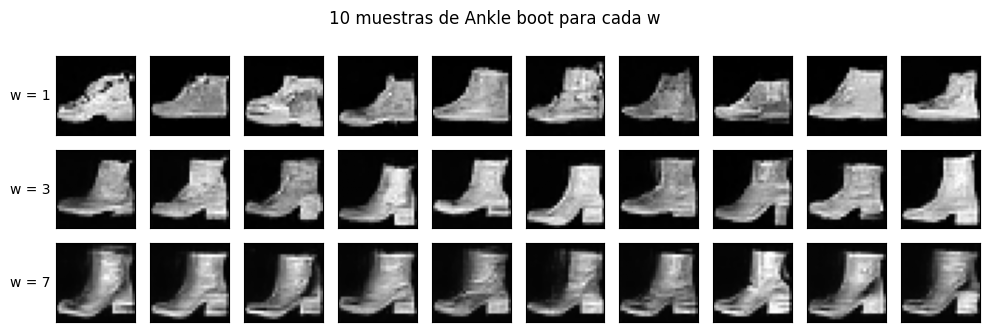

In [12]:
fig, axes = plt.subplots(len(W_VALUES), 10, figsize=(10, 3.4))
for row, w in enumerate(W_VALUES):
    imgs = cfg_samples[w][cfg_labels == focus_class][:10].cpu()
    for j in range(10):
        ax = axes[row, j]
        ax.imshow((imgs[j, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(f"w = {w}", rotation=0, ha="right", va="center")
fig.suptitle(f"10 muestras de {labels_names[focus_class]} para cada w")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "muestras_clase_por_w.png", dpi=120)
plt.show()

### 5.5 Matriz de confusión con $w=1$

Filas = clase pedida, columnas = clase que asigna el clasificador. El par más confundido se toma como el de mayor suma de errores en ambas direcciones.

filas = clase pedida, columnas = clase predicha
tensor([[42,  0,  1,  0,  0,  0,  7,  0,  0,  0],
        [ 0, 47,  0,  3,  0,  0,  0,  0,  0,  0],
        [ 0,  0, 33,  0,  9,  0,  8,  0,  0,  0],
        [ 1,  1,  0, 45,  1,  0,  2,  0,  0,  0],
        [ 0,  0,  1,  2, 42,  0,  5,  0,  0,  0],
        [ 0,  0,  0,  0,  0, 47,  0,  2,  0,  1],
        [ 1,  0,  7,  2,  8,  0, 32,  0,  0,  0],
        [ 0,  0,  0,  0,  0,  5,  0, 40,  2,  3],
        [ 0,  0,  1,  0,  0,  2,  0,  0, 46,  1],
        [ 0,  0,  0,  0,  0,  1,  0,  4,  0, 45]])

Par más confundido: Pullover <-> Shirt (8 de Pullover como Shirt, 7 de Shirt como Pullover)


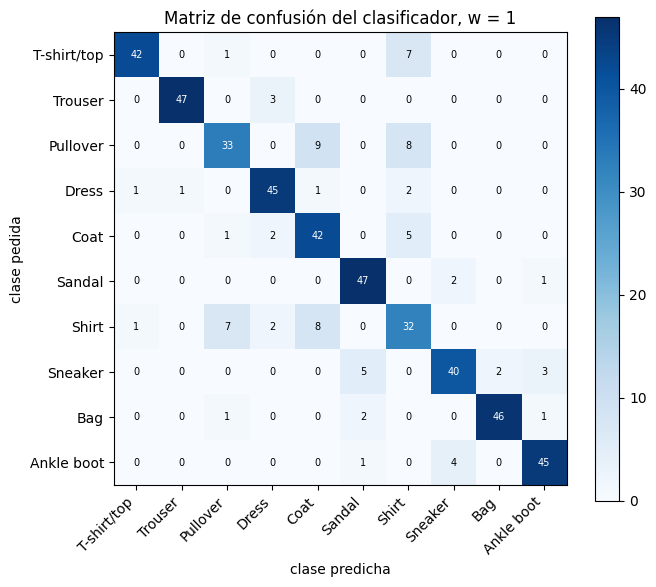

In [13]:
preds_w1 = predict(classifier, cfg_samples[1])
cm = confusion_matrix(preds_w1, cfg_labels)
print("filas = clase pedida, columnas = clase predicha")
print(cm)

symmetric = (cm + cm.T).float()
symmetric.fill_diagonal_(-1)
a, b = divmod(int(symmetric.argmax()), 10)
print(f"\nPar más confundido: {labels_names[a]} <-> {labels_names[b]} "
      f"({cm[a, b].item()} de {labels_names[a]} como {labels_names[b]}, "
      f"{cm[b, a].item()} de {labels_names[b]} como {labels_names[a]})")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), labels_names, rotation=45, ha="right")
ax.set_yticks(range(10), labels_names)
ax.set_xlabel("clase predicha")
ax.set_ylabel("clase pedida")
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im, ax=ax)
ax.set_title("Matriz de confusión del clasificador, w = 1")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_w1.png", dpi=120)
plt.show()

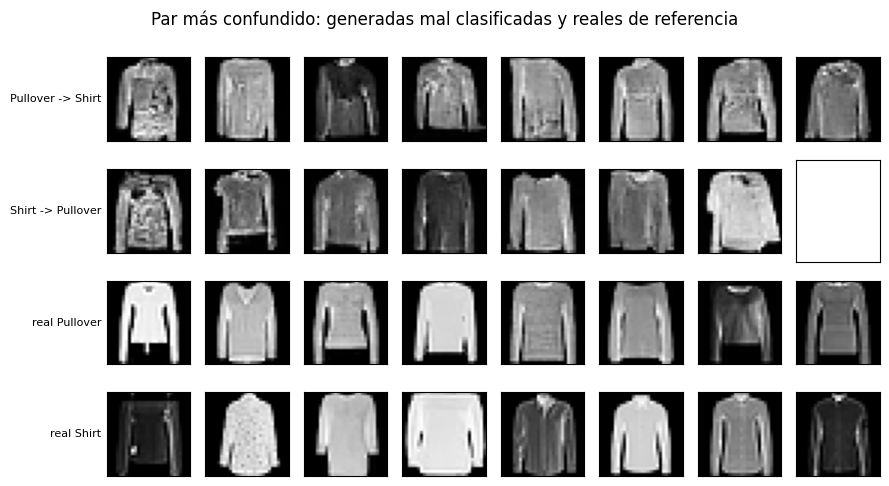

Pullover -> Shirt: 8 imágenes
Shirt -> Pullover: 7 imágenes


In [14]:
# imágenes del par: generadas que se confunden en cada dirección y reales de cada clase
cpu_labels, cpu_preds = cfg_labels.cpu(), preds_w1.cpu()
rows = [
    (f"{labels_names[a]} -> {labels_names[b]}", cfg_samples[1].cpu()[(cpu_labels == a) & (cpu_preds == b)]),
    (f"{labels_names[b]} -> {labels_names[a]}", cfg_samples[1].cpu()[(cpu_labels == b) & (cpu_preds == a)]),
    (f"real {labels_names[a]}", real_imgs[real_labels == a]),
    (f"real {labels_names[b]}", real_imgs[real_labels == b]),
]
fig, axes = plt.subplots(len(rows), 8, figsize=(9, 5))
for r, (name, imgs) in enumerate(rows):
    for j in range(8):
        ax = axes[r, j]
        ax.set_xticks([])
        ax.set_yticks([])
        if j < len(imgs):
            ax.imshow((imgs[j, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
        if j == 0:
            ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
fig.suptitle("Par más confundido: generadas mal clasificadas y reales de referencia")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "par_confundido.png", dpi=120)
plt.show()
for name, imgs in rows[:2]:
    print(f"{name}: {len(imgs)} imágenes")

Para separar un defecto del generador de uno del clasificador o de las clases, medimos cuánto confunde el clasificador ese mismo par en las 5 000 imágenes **reales** de validación.

In [15]:
cm_real = confusion_matrix(predict(classifier, x_val_dev), y_val_dev)
n_a, n_b = cm_real[a].sum().item(), cm_real[b].sum().item()
print(f"real {labels_names[a]} como {labels_names[b]}: {cm_real[a, b].item()} de {n_a} "
      f"({cm_real[a, b].item() / n_a:.1%})")
print(f"real {labels_names[b]} como {labels_names[a]}: {cm_real[b, a].item()} de {n_b} "
      f"({cm_real[b, a].item() / n_b:.1%})")
print(f"generadas w=1 {labels_names[a]} como {labels_names[b]}: {cm[a, b].item()} de 50 ({cm[a, b].item() / 50:.1%})")
print(f"generadas w=1 {labels_names[b]} como {labels_names[a]}: {cm[b, a].item()} de 50 ({cm[b, a].item() / 50:.1%})")
print("\nexactitud por clase en reales:")
for k in range(10):
    print(f"  {labels_names[k]:>12}: {cm_real[k, k].item() / cm_real[k].sum().item():.1%}")

real Pullover como Shirt: 49 de 490 (10.0%)
real Shirt como Pullover: 19 de 467 (4.1%)
generadas w=1 Pullover como Shirt: 8 de 50 (16.0%)
generadas w=1 Shirt como Pullover: 7 de 50 (14.0%)

exactitud por clase en reales:
   T-shirt/top: 81.8%
       Trouser: 98.2%
      Pullover: 75.3%
         Dress: 93.7%
          Coat: 88.0%
        Sandal: 97.6%
         Shirt: 70.0%
       Sneaker: 96.4%
           Bag: 99.0%
    Ankle boot: 95.2%


## 6. Artefactos para la Task 4

La Task 4.1 usa las imágenes generadas aquí y vuelve a generar con la red. Como `checkpoints/` y `outputs/` no se versionan, guardamos en `artifacts/task3/` los pesos finales de la U-Net y las 1 500 imágenes de la Task 3.4 en `uint8` (de $[-1,1]$ a $[0,255]$). Ambos archivos se cargan con `weights_only=True`.

In [16]:
weights_path = ARTIFACT_DIR / "unet_cfg.pt"
samples_path = ARTIFACT_DIR / "muestras_cfg.pt"


def to_uint8(x):
    return ((x.cpu() + 1) / 2 * 255).round().clamp(0, 255).to(torch.uint8)


torch.save(model.state_dict(), weights_path)
torch.save({"labels": cfg_labels.cpu(), **{f"w{w}": to_uint8(cfg_samples[w]) for w in W_VALUES}},
           samples_path)

# comprobación 1: los pesos guardados son exactamente los del modelo
saved_weights = torch.load(weights_path, map_location=DEVICE, weights_only=True)
same_weights = all(torch.equal(saved_weights[k], v) for k, v in model.state_dict().items())

# comprobación 2: el modelo recargado predice lo mismo. en gpu cudnn puede elegir
# otro algoritmo de convolucion, asi que se compara con tolerancia de float32
reloaded = UNet(emb_dim=128).to(DEVICE)
reloaded.load_state_dict(saved_weights)
reloaded.eval()
model.eval()
with torch.no_grad():
    diff = (model(x_probe, t_probe, c_probe) - reloaded(x_probe, t_probe, c_probe)).abs().max().item()
saved = torch.load(samples_path, weights_only=True)
print("pesos idénticos tras recargar:", same_weights)
print(f"diferencia máxima entre predicciones: {diff:.2e}")
print("contenido de muestras:", {k: tuple(v.shape) for k, v in saved.items()})
for path in (weights_path, samples_path):
    print(f"{path.name}: {path.stat().st_size / 1e6:.2f} MB")
assert same_weights and diff < 1e-4

pesos idénticos tras recargar: True
diferencia máxima entre predicciones: 9.54e-07
contenido de muestras: {'labels': (500,), 'w1': (500, 1, 28, 28), 'w3': (500, 1, 28, 28), 'w7': (500, 1, 28, 28)}
unet_cfg.pt: 1.60 MB
muestras_cfg.pt: 1.18 MB


## 7. Task 3.5 - respuestas

### a. Fidelidad y diversidad al aumentar $w$

Al subir $w$ la fidelidad crece de 0.838 con $w=1$ a 0.986 con $w=3$ y 0.998 con $w=7$, por encima de la fidelidad de las imágenes reales (0.880). La diversidad cae de 16.182 a 14.000 y 12.942, mientras la de las reales es 17.675. Más guía produce imágenes más fáciles de reconocer y más parecidas entre sí.

La clase con mayor caída es Ankle boot, de 16.366 a 10.011, una caída de 6.355. La hipótesis es que la guía empuja cada muestra hacia la zona donde la clase es inequívoca, y en Ankle boot esa zona es estrecha porque la clase limita con Sneaker y Sandal. Con $w=1$ la matriz de confusión registra 4 Ankle boot generadas como Sneaker y 1 como Sandal. En la figura de 10 muestras, con $w=1$ aparecen botas bajas con cordones y suela plana que se parecen a un tenis, y con $w=7$ casi todas son la misma bota alta de tacón cuadrado. La guía elimina justo las variantes cercanas a Sneaker, que eran las que aportaban variedad.

### b. Matriz de confusión con $w=1$

El par más confundido es Pullover y Shirt, con 8 Pullover generadas clasificadas como Shirt y 7 Shirt clasificadas como Pullover. En las imágenes reales de validación el clasificador también los confunde, con 10.0 % de Pullover como Shirt y 4.1 % de Shirt como Pullover, y son sus dos clases de menor exactitud (75.3 % y 70.0 %). En clases de silueta inconfundible como Trouser y Bag llega a 98.2 % y 99.0 %.

La confusión viene principalmente de las propias clases. En la figura del par, las reales de ambas clases comparten la silueta de manga larga y se distinguen sobre todo por el cuello y la línea de botones de la camisa. El modelo generativo agrava el problema, sobre todo de Shirt hacia Pullover, que pasa de 4.1 % en reales a 14.0 % en generadas. Las camisas generadas mal clasificadas no muestran un cuello ni botones visibles y quedan como un suéter liso. El clasificador aporta error, pero ese error nace de la semejanza entre las clases y no de un fallo general, porque su exactitud global es 89.64 %.

### c. La guía como muestreo de $\tilde p(x\mid c)\propto p(x)\,p(c\mid x)^w$

Al tomar el logaritmo y el gradiente respecto a $x$, la constante de normalización desaparece porque no depende de $x$.

$$\nabla_x\log\tilde p(x\mid c)=\nabla_x\log p(x)+w\,\nabla_x\log p(c\mid x)$$

Por la regla de Bayes $p(c\mid x)=p(x\mid c)\,p(c)/p(x)$, y como $p(c)$ no depende de $x$,

$$\nabla_x\log p(c\mid x)=\nabla_x\log p(x\mid c)-\nabla_x\log p(x).$$

Al sustituir,

$$\nabla_x\log\tilde p(x\mid c)=\nabla_x\log p(x)+w\bigl(\nabla_x\log p(x\mid c)-\nabla_x\log p(x)\bigr).$$

Con $s\approx-\epsilon_\theta/\sqrt{1-\bar\alpha_t}$ el score incondicional es $-\epsilon_\theta(x_t,t,\varnothing)/\sqrt{1-\bar\alpha_t}$ y el condicional es $-\epsilon_\theta(x_t,t,c)/\sqrt{1-\bar\alpha_t}$. Multiplicando toda la igualdad por $-\sqrt{1-\bar\alpha_t}$ queda

$$\tilde\epsilon=\epsilon_\theta(x_t,t,\varnothing)+w\bigl(\epsilon_\theta(x_t,t,c)-\epsilon_\theta(x_t,t,\varnothing)\bigr),$$

que es la predicción guiada. Con $w=1$ se recupera $p(x)\,p(c\mid x)\propto p(x\mid c)$, el modelo condicional puro. Con $w>1$ la probabilidad $p(c\mid x)$, que es menor que 1, se eleva a una potencia mayor. Eso castiga más las regiones donde la clase es dudosa y concentra la masa donde $p(c\mid x)$ es cercana a 1. La distribución se vuelve más estrecha, y por eso la diversidad cae de 16.182 con $w=1$ a 12.942 con $w=7$ mientras la fidelidad llega a 0.998.

### d. Pérdida por intervalo de $t$

La pérdida es mayor en el intervalo 1-100 (0.2166) y menor en 801-900 y 901-1000 (0.0007), y disminuye de un intervalo al siguiente hasta estabilizarse en 0.0007. En $t$ pequeño el SNR es muy alto, $x_t$ es casi $x_0$ y el ruido es una perturbación diminuta que hay que separar de los detalles finos de la prenda. En $t$ grande el SNR es menor que 0.01, $x_t\approx\epsilon$ y predecir $\epsilon$ es casi copiar la entrada.

En la Task 2.5b el calendario lineal tiene 326 pasos con SNR menor que 0.01 (de $t=675$ en adelante), 27 con SNR mayor que 100 y 647 útiles entre $t=28$ y $t=674$. El comportamiento coincide en el régimen de SNR bajo, porque los intervalos de 701 a 1000 tienen pérdida de 0.0013 o menos y aportan muy poca señal de aprendizaje. No coincide en el régimen de SNR alto. La Task 2.5b suponía que predecir el ruido con SNR mayor que 100 era trivial, pero el intervalo 1-100 es el más difícil, con 0.2166 frente a 0.0007 en el intervalo 901-1000. La franja útil sí coincide, porque los intervalos de 101 a 700 tienen pérdidas intermedias, entre 0.0828 y 0.0032.

## 8. Registro de uso de IA (Task 3)

**Prompt utilizado**

> ok, o versionamos eso y ya, no sé. lo que convenga. hace el plan por fases, subfases, criterios de aceptacion, solid, dry, yagni, kiss. NO ASUMAS NADA

**Qué se usó**

El plan por fases de la Task 3, el módulo `src/difusion.py` con sus pruebas, este notebook y la redacción de las respuestas de la Task 3.5 a partir de los outputs ejecutados.

**Por qué funcionó**

El prompt exige criterios de aceptación verificables y prohíbe suponer datos. Cada fórmula del módulo tiene una prueba que la compara con un cálculo a mano o con los valores ya impresos en la Task 2. Cada cifra de las respuestas sale de los outputs de este notebook, y la respuesta 3.5b se respaldó con una celda adicional que mide la confusión del clasificador en imágenes reales en lugar de suponerla.